In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split , KFold , cross_val_score , GridSearchCV
from sklearn.metrics import classification_report , confusion_matrix
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier , AdaBoostClassifier
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('diabetes.csv')
df_names = df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB


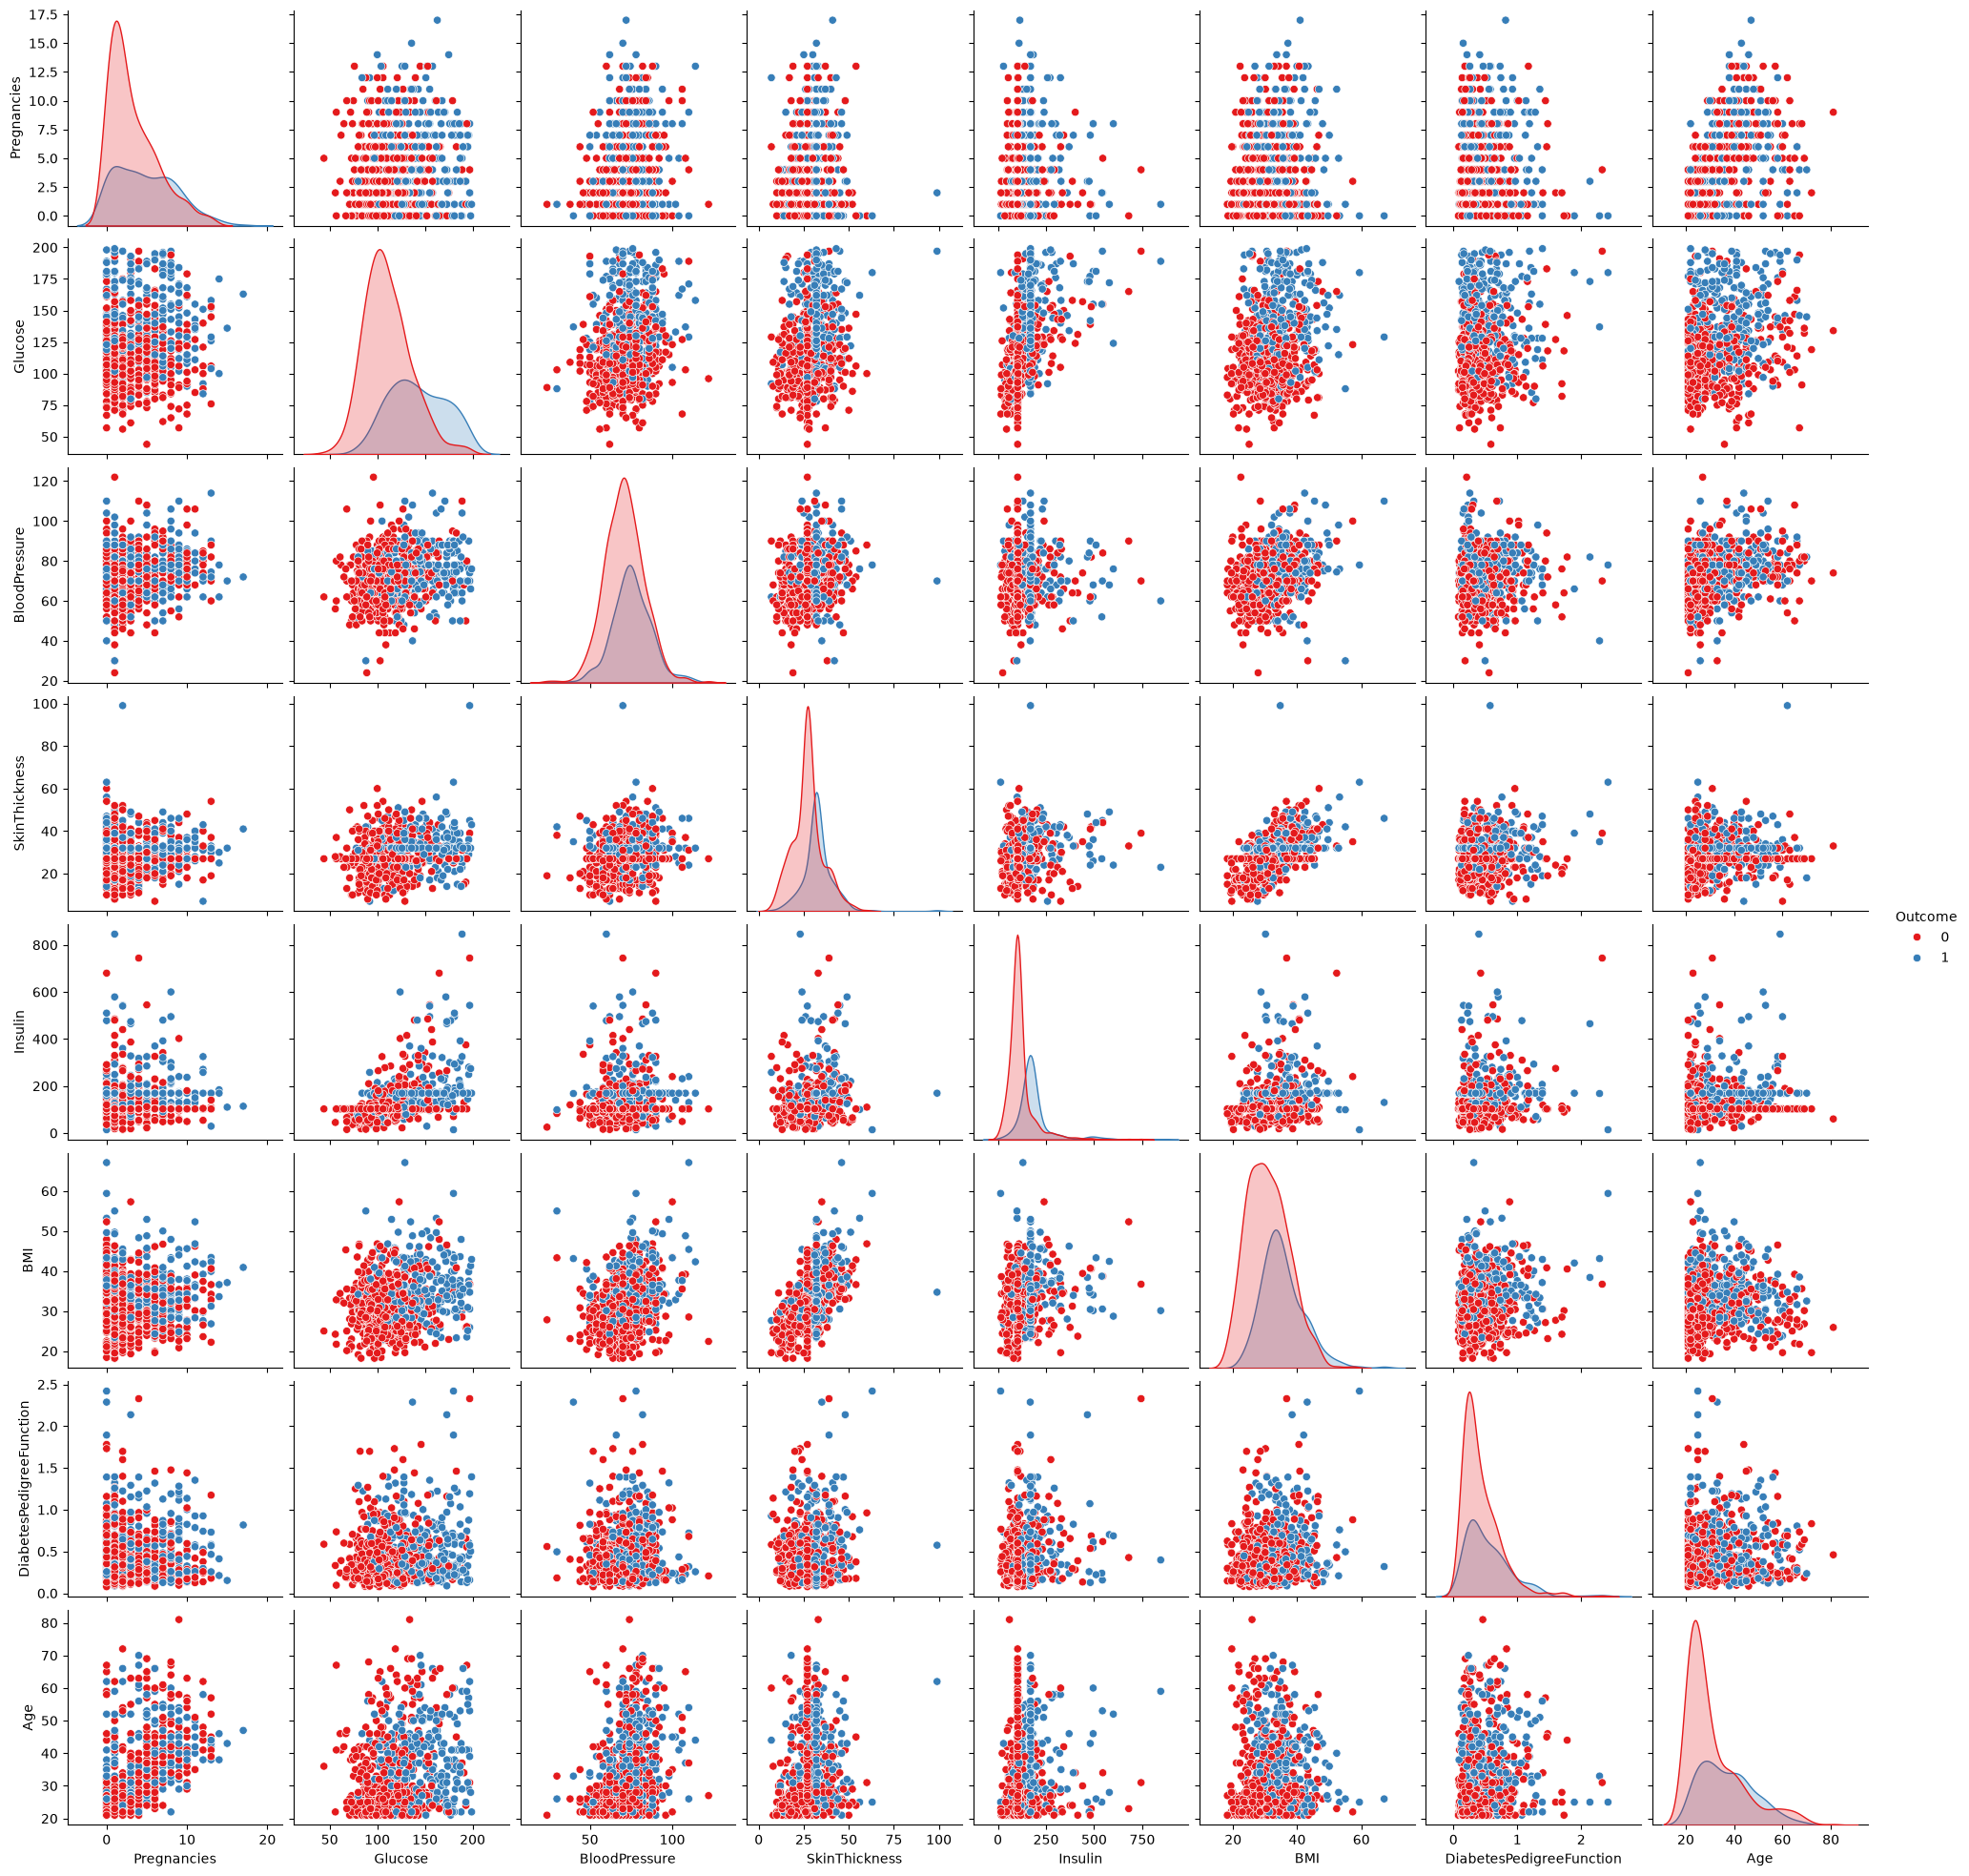

In [3]:
sns.pairplot(df, hue='Outcome', palette='Set1')


<Axes: >

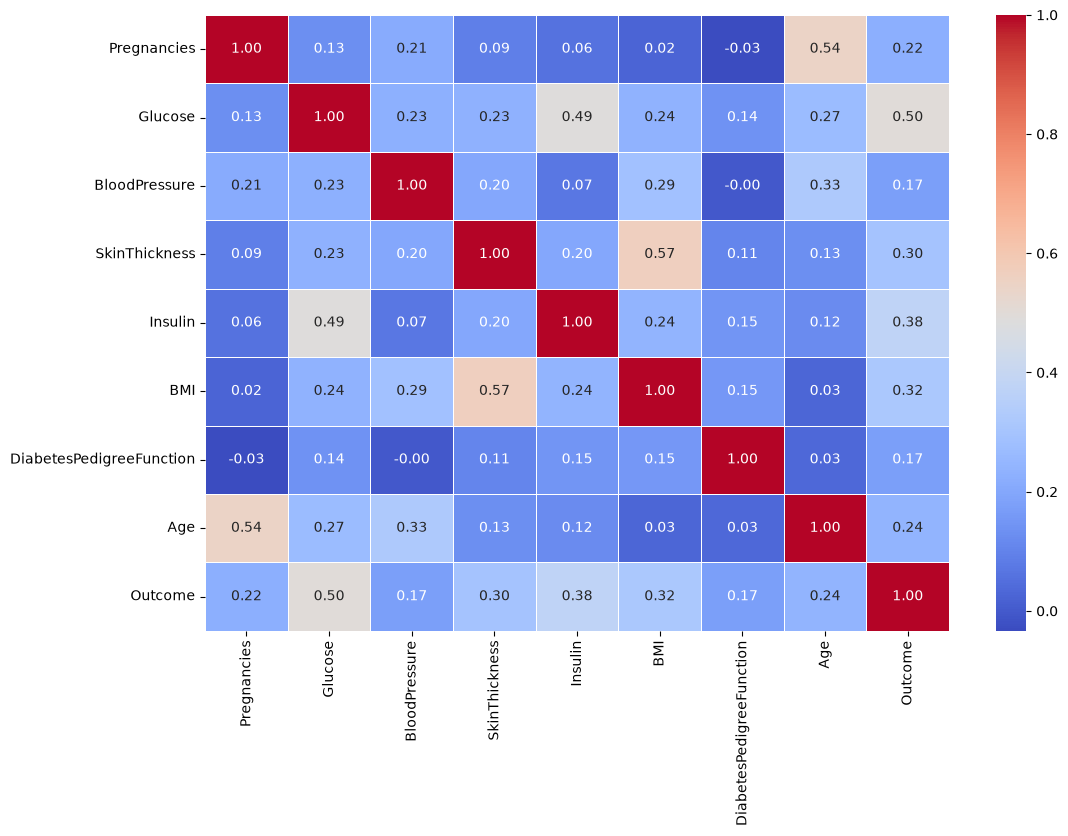

In [4]:
corr_matrix = df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

In [6]:
# Outlier Detection and Removal

def detect_outliers(df):
    outlier_indices = []
    outliers_df = pd.DataFrame()
    
    for feature in df.select_dtypes(include=[np.number]).columns:
        Q1 = np.percentile(df[feature], 25)
        Q3 = np.percentile(df[feature], 75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers = df[(df[feature] < lower_bound) | (df[feature] > upper_bound)].index
        outliers_df = pd.concat([outliers_df, df.loc[outliers]])
        outlier_indices.extend(outliers)
    outliers_df= outliers_df.drop_duplicates(inplace=True)
    return outliers_df, list(set(outlier_indices))
outliers_df, outlier_indices = detect_outliers(df)

In [7]:
df_cleaned = df.drop(outlier_indices, axis=0).reset_index(drop=True)

In [8]:
# Model Training and Testing

X = df_cleaned.drop('Outcome', axis=1)
y = df_cleaned['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
def getBasedModels():
    models = {
        'Logistic Regression': LogisticRegression(),
        'Decision Tree': DecisionTreeClassifier(),
        'K-Nearest Neighbors': KNeighborsClassifier(),
        'Naive Bayes': GaussianNB(),
        'Support Vector Machine': SVC(),
        'Random Forest': RandomForestClassifier(),
        'Gradient Boosting': GradientBoostingClassifier(),
        'AdaBoost': AdaBoostClassifier()
    }
    return models
def baseModelsTraining(X_train, y_train,models):
    results = []
    names = []
    
    for name, model in models:
        kfold = KFold(n_splits=10, shuffle=True, random_state=42)
        cv_results = cross_val_score(model, X_train, y_train, cv=kfold, scoring='accuracy')
        results.append(cv_results)
        names.append(name)
        print(f"{name}: {cv_results.mean():.4f} ({cv_results.std():.4f})")
    return results, names

def plot_box(names, results):
    df= pd.DataFrame({names[i]: results[i] for i in range(len(names))})
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df)
    plt.title('Algorithm Comparison')
    plt.xlabel('Algorithm')
    plt.ylabel('Accuracy')
    plt.show()

Logistic Regression: 0.8791 (0.0358)
Decision Tree: 0.8857 (0.0489)
K-Nearest Neighbors: 0.8792 (0.0504)
Naive Bayes: 0.8727 (0.0476)
Support Vector Machine: 0.8982 (0.0465)
Random Forest: 0.9046 (0.0383)
Gradient Boosting: 0.8984 (0.0373)
AdaBoost: 0.9068 (0.0436)


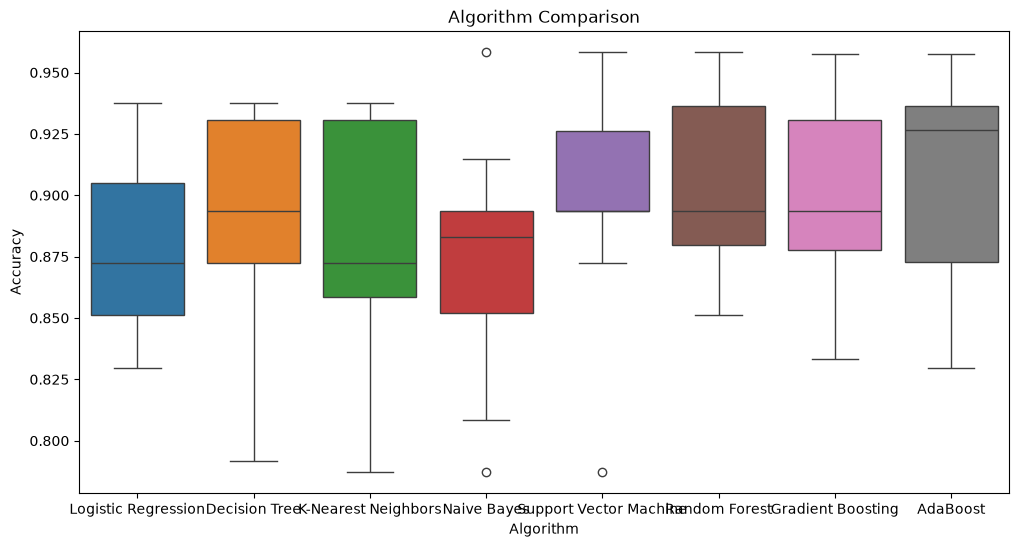

In [18]:
models = getBasedModels()
results, names = baseModelsTraining(X_train_scaled, y_train, models.items())
plot_box(names, results)

In [21]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [10,20,30,40,50],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]}

dt = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)
print(f"Best parameters: {grid_search.best_params_}")
best_dt = grid_search.best_estimator_
y_pred = best_dt.predict(X_test_scaled)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Best parameters: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}
Confusion Matrix:
[[68  4]
 [14 32]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.94      0.88        72
           1       0.89      0.70      0.78        46

    accuracy                           0.85       118
   macro avg       0.86      0.82      0.83       118
weighted avg       0.85      0.85      0.84       118



In [22]:
# Model Testing
new_data = pd.DataFrame({
    'Pregnancies': [2],
    'Glucose': [120],
    'BloodPressure': [70],
    'SkinThickness': [20],
    'Insulin': [79],
    'BMI': [25.0],
    'DiabetesPedigreeFunction': [0.5],
    'Age': [30]
})
new_data_scaled = scaler.transform(new_data)
new_prediction = best_dt.predict(new_data_scaled)
print(f"Prediction for new data: {'Diabetic' if new_prediction[0] == 1 else 'Non-Diabetic'}")

Prediction for new data: Non-Diabetic
